# DATA3001 Region A Preliminary Analysis

This notebook converts the `regionA_final.py` workflow into cells that can be
run one at a time. It analyses Global Drifter Program observations in Region A
(125–135°E, 25–35°N), checks data quality, uses the official eastward and
northward velocity fields when available, and produces two preliminary figures.

**Data requirement:** the full NOAA export is kept locally as `RegionA.csv`
(preferred) or `data/regions/region_A.csv`. The raw CSV is not uploaded to
GitHub because it is a large downloaded data file.

## 1. Imports and configuration

Run the notebook from the repository root. Figures are saved under
`outputs/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LON_MIN, LON_MAX = 125.0, 135.0
LAT_MIN, LAT_MAX = 25.0, 35.0
EARTH_RADIUS_M = 6_371_000.0


def find_project_root(start: Path | None = None) -> Path:
    """Find the repository containing a supported Region A CSV."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        full_export = candidate / "RegionA.csv"
        legacy_export = candidate / "data" / "regions" / "region_A.csv"
        if full_export.exists() or legacy_export.exists():
            return candidate
    raise FileNotFoundError(
        "Could not find RegionA.csv or data/regions/region_A.csv. Start "
        "JupyterLab from the data3001-project folder and make sure the CSV is "
        "present."
    )


PROJECT_DIR = find_project_root()
FULL_DATA_PATH = PROJECT_DIR / "RegionA.csv"
LEGACY_DATA_PATH = PROJECT_DIR / "data" / "regions" / "region_A.csv"
DATA_PATH = FULL_DATA_PATH if FULL_DATA_PATH.exists() else LEGACY_DATA_PATH
OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Data:", DATA_PATH)
print("Figures:", OUTPUT_DIR)

Project: /Users/roger/Documents/data3001-project
Data: /Users/roger/Documents/data3001-project/RegionA.csv
Figures: /Users/roger/Documents/data3001-project/outputs/figures


## 2. Load the Region A CSV

NOAA ERDDAP exports may contain a units row immediately below the header. The
cell detects and skips that row automatically.

In [2]:
preview = pd.read_csv(DATA_PATH, nrows=1, low_memory=False)
skip_units = False
if "latitude" in preview.columns and not preview.empty:
    skip_units = pd.isna(
        pd.to_numeric(preview.loc[0, "latitude"], errors="coerce")
    )

raw = pd.read_csv(
    DATA_PATH,
    skiprows=[1] if skip_units else None,
    low_memory=False,
)

print(f"Loaded {len(raw):,} rows and {len(raw.columns)} columns")
print("Columns:", raw.columns.tolist())
raw.head()

Loaded 562,944 rows and 20 columns
Columns: ['ID', 'time', 'latitude', 'longitude', 'sst', 'flg_sst', 've', 'vn', 'err_lat', 'err_lon', 'err_ve', 'err_vn', 'gap', 'deploy_lat', 'deploy_lon', 'drogue_lost_date', 'location_type', 'DeployingShip', 'DrogueType', 'DrogueCenterDepth']


,ID,time,latitude,longitude,sst,flg_sst,ve,vn,err_lat,err_lon,err_ve,err_vn,gap,deploy_lat,deploy_lon,drogue_lost_date,location_type,DeployingShip,DrogueType,DrogueCenterDepth
0,116418,2015-08-23T21:00:00Z,25.25155,134.60040,NaN,0.0,0.3281,0.3371,1.630000e-07,4.122000e-07,0.0487,0.0628,1681.2083,6.16,-153.65,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m
1,116418,2015-08-23T22:00:00Z,25.26250,134.61234,NaN,0.0,0.3280,0.3372,1.437000e-07,4.155000e-07,0.0484,0.0628,1681.2083,6.16,-153.65,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m
2,116418,2015-08-23T23:00:00Z,25.27344,134.62427,NaN,0.0,0.3280,0.3372,1.269000e-07,3.766000e-07,0.0826,0.0628,1681.2083,6.16,-153.65,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m
3,116418,2015-08-24T00:00:00Z,25.28436,134.63625,NaN,0.0,0.3280,0.3372,1.140000e-07,3.698000e-07,0.0826,0.0628,1681.2083,6.16,-153.65,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m
4,116418,2015-08-24T01:00:00Z,25.29527,134.64825,NaN,0.0,0.3280,0.3372,1.063000e-07,5.495000e-07,0.0664,0.0628,1681.2083,6.16,-153.65,2014-07-27T00:00:00Z,Argos,USCG,HOLY217,15 m


## 3. Clean coordinates and calculate speed

If the downloaded file already contains eastward (`ve`) and northward (`vn`)
velocity, those fields are used. Otherwise, velocity is estimated from the
change between consecutive hourly positions of the same drifter.

In [3]:
required = {"ID", "time", "latitude", "longitude"}
missing_required = required.difference(raw.columns)
if missing_required:
    raise ValueError(f"Required columns are missing: {sorted(missing_required)}")

df = raw.copy()
df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")

for column in ["latitude", "longitude", "ve", "vn"]:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

df["lon"] = ((df["longitude"] + 180.0) % 360.0) - 180.0
df["lat"] = df["latitude"]
df = df.dropna(subset=["ID", "time", "lat", "lon"]).copy()
df = df.sort_values(["ID", "time"]).reset_index(drop=True)

if {"ve", "vn"}.issubset(df.columns):
    df["speed"] = np.hypot(df["ve"], df["vn"])
    speed_source = "provided ve/vn columns"
else:
    grouped = df.groupby("ID", sort=False)
    time_difference_s = grouped["time"].diff().dt.total_seconds()
    previous_lat = grouped["lat"].shift()
    previous_lon = grouped["lon"].shift()

    latitude_change = np.deg2rad(df["lat"] - previous_lat)
    longitude_change = np.deg2rad(df["lon"] - previous_lon)
    mean_latitude = np.deg2rad((df["lat"] + previous_lat) / 2.0)

    # Only use steps that are approximately one hour apart.
    valid_hourly_step = time_difference_s.between(0.5 * 3600, 1.5 * 3600)
    df["vn"] = np.where(
        valid_hourly_step,
        EARTH_RADIUS_M * latitude_change / time_difference_s,
        np.nan,
    )
    df["ve"] = np.where(
        valid_hourly_step,
        EARTH_RADIUS_M * np.cos(mean_latitude) * longitude_change
        / time_difference_s,
        np.nan,
    )
    df["speed"] = np.hypot(df["ve"], df["vn"])
    speed_source = "estimated from consecutive positions"

print("Rows after cleaning:", f"{len(df):,}")
print("Speed source:", speed_source)
df.head()

Rows after cleaning: 562,944
Speed source: provided ve/vn columns


,ID,time,latitude,longitude,sst,flg_sst,ve,vn,err_lat,err_lon,...,deploy_lat,deploy_lon,drogue_lost_date,location_type,DeployingShip,DrogueType,DrogueCenterDepth,lon,lat,speed
0,4888,2002-10-09 00:00:00+00:00,34.90803,129.26541,290.125,5.0,0.4674,0.7652,7.493000e-07,1.318000e-07,...,34.917,129.267,2002-10-19T00:00:00Z,Argos,Directory file,HOLY124,15 m,129.26541,34.90803,0.896657
1,4888,2002-10-09 01:00:00+00:00,34.93290,129.28381,291.206,5.0,0.4672,0.7651,6.850000e-07,1.258000e-07,...,34.917,129.267,2002-10-19T00:00:00Z,Argos,Directory file,HOLY124,15 m,129.28381,34.93290,0.896467
2,4888,2002-10-09 02:00:00+00:00,34.95778,129.30219,292.889,5.0,0.4670,0.7649,6.348000e-07,1.206000e-07,...,34.917,129.267,2002-10-19T00:00:00Z,Argos,Directory file,HOLY124,15 m,129.30219,34.95778,0.896193
3,4888,2002-10-09 03:00:00+00:00,34.98266,129.32048,294.798,5.0,0.4667,0.7646,5.778000e-07,1.162000e-07,...,34.917,129.267,2002-10-19T00:00:00Z,Argos,Directory file,HOLY124,15 m,129.32048,34.98266,0.895780
4,35554,2012-09-02 06:00:00+00:00,26.54376,125.00968,304.229,5.0,0.8110,0.0177,1.850000e-08,1.519000e-07,...,11.910,133.750,2012-07-23T00:00:00Z,Argos,UNKNOWN,HOLY214,15 m,125.00968,26.54376,0.811193


## 4. Dataset overview

In [4]:
overview = pd.Series(
    {
        "observations": len(df),
        "unique_drifters": df["ID"].nunique(),
        "start_time": df["time"].min(),
        "end_time": df["time"].max(),
        "speed_source": speed_source,
    },
    name="Region A",
)
overview.to_frame()

,Region A
observations,562944
unique_drifters,521
start_time,1994-07-10 12:00:00+00:00
end_time,2022-10-31 00:00:00+00:00
speed_source,provided ve/vn columns


## 5. Missing-value audit

In [5]:
qc_candidates = [
    "ID",
    "time",
    "latitude",
    "longitude",
    "ve",
    "vn",
    "err_lat",
    "err_lon",
    "err_ve",
    "err_vn",
    "gap",
    "location_type",
    "drogue_lost_date",
    "DrogueType",
    "DrogueCenterDepth",
]
qc_columns = [column for column in qc_candidates if column in df.columns]

missing_table = pd.DataFrame(
    {
        "missing_n": df[qc_columns].isna().sum(),
        "missing_pct": df[qc_columns].isna().mean().mul(100),
    }
).round(3)

missing_table

,missing_n,missing_pct
ID,0,0.000
time,0,0.000
latitude,0,0.000
longitude,0,0.000
ve,0,0.000
vn,0,0.000
err_lat,1049,0.186
err_lon,1052,0.187
err_ve,24624,4.374
err_vn,24630,4.375


## 6. Position and velocity summary

Extreme estimated speeds should be reviewed during later quality control; a
very large value can be caused by a position jump rather than a real current.

In [6]:
summary_columns = [
    column
    for column in [
        "latitude",
        "longitude",
        "ve",
        "vn",
        "speed",
        "err_lat",
        "err_lon",
        "err_ve",
        "err_vn",
    ]
    if column in df.columns
]

distribution_table = (
    df[summary_columns]
    .describe(percentiles=[0.01, 0.50, 0.90, 0.95, 0.99, 0.999])
    .T
)
distribution_table

,count,mean,std,min,1%,50%,90%,95%,99%,99.9%,max
latitude,562944.0,2.875797e+01,2.368494e+00,2.500002e+01,2.506748e+01,2.865791e+01,3.194187e+01,3.277567e+01,3.471024e+01,3.497098e+01,34.999980
longitude,562944.0,1.300987e+02,2.899442e+00,1.250000e+02,1.251194e+02,1.300871e+02,1.339979e+02,1.344987e+02,1.349022e+02,1.349903e+02,135.000000
ve,562944.0,1.123787e-01,3.598581e-01,-1.786500e+00,-6.367000e-01,7.370000e-02,5.714000e-01,7.700000e-01,1.170802e+00,1.682300e+00,2.317500
vn,562944.0,1.077158e-01,3.452925e-01,-1.772700e+00,-6.757000e-01,8.248331e-02,5.556000e-01,7.289000e-01,1.054557e+00,1.418646e+00,2.395700
speed,562944.0,4.272750e-01,3.006531e-01,0.000000e+00,3.171199e-02,3.540085e-01,8.416562e-01,1.038358e+00,1.425200e+00,1.859182e+00,2.509400
err_lat,561895.0,-2.135298e-04,4.621238e-02,-9.999990e+00,2.500000e-09,1.610000e-08,7.259999e-08,1.094000e-07,2.260000e-07,4.929212e-07,0.000580
err_lon,561892.0,4.258520e-08,6.508644e-08,9.999999e-11,3.200000e-09,2.260000e-08,1.028000e-07,1.502000e-07,2.936000e-07,6.209327e-07,0.000006
err_ve,538320.0,5.556101e-02,6.720350e-02,2.430557e-06,3.400000e-03,3.190000e-02,1.303000e-01,1.795000e-01,3.140000e-01,5.913000e-01,3.051200
err_vn,538314.0,4.082405e-02,4.715248e-02,2.430557e-06,2.800000e-03,2.330000e-02,9.210000e-02,1.281000e-01,2.269000e-01,4.300748e-01,1.459400


## 7. Region boundary and positioning-system checks

In [7]:
outside_region = (
    ~df["lon"].between(LON_MIN, LON_MAX)
    | ~df["lat"].between(LAT_MIN, LAT_MAX)
)

boundary_check = pd.Series(
    {
        "outside_region_n": int(outside_region.sum()),
        "outside_region_pct": outside_region.mean() * 100,
    }
)
display(boundary_check.to_frame("value"))

if "location_type" in df.columns:
    location_counts = df["location_type"].value_counts(dropna=False)
    location_table = pd.DataFrame(
        {
            "count": location_counts,
            "percentage": (
                df["location_type"]
                .value_counts(normalize=True, dropna=False)
                .mul(100)
            ),
        }
    ).round(2)
    display(location_table)
else:
    print("location_type is not available in this CSV; this check was skipped.")

,value
outside_region_n,0.0
outside_region_pct,0.0


,count,percentage
location_type,,
Argos,401989,71.41
GPS,160955,28.59


## 8. Speed distribution

In [8]:
speed_values = df["speed"].replace([np.inf, -np.inf], np.nan).dropna()
display_limit = speed_values.quantile(0.999)
speed_values_for_plot = speed_values[speed_values <= display_limit]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(speed_values_for_plot, bins=100, color="#2878B5", edgecolor="none")
ax.set_xlabel("Speed (m/s)")
ax.set_ylabel("Number of observations")
ax.set_title("Region A — Drifter Speed Distribution\n(up to the 99.9th percentile)")
fig.tight_layout()

speed_histogram_path = OUTPUT_DIR / "region_A_speed_distribution.png"
fig.savefig(speed_histogram_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", speed_histogram_path)
print(f"Display limit (99.9th percentile): {display_limit:.3f} m/s")

Saved: /Users/roger/Documents/data3001-project/outputs/figures/region_A_speed_distribution.png
Display limit (99.9th percentile): 1.859 m/s


/var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/ipykernel_27902/1332963645.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 9. Optional high-resolution land-mask check

`global-land-mask` expands a compressed global grid in memory and may use
about 1 GB of RAM. It is disabled by default so that **Run All Cells** remains
safe on typical laptops. Change `USE_LAND_MASK` to `True` only when needed.

In [9]:
USE_LAND_MASK = False

if USE_LAND_MASK:
    from global_land_mask import globe

    is_land = globe.is_land(df["lat"].to_numpy(), df["lon"].to_numpy())
    land_observations = df.loc[is_land]
    land_summary = pd.Series(
        {
            "land_observations": len(land_observations),
            "land_percentage": 100 * len(land_observations) / len(df),
            "drifters_involved": land_observations["ID"].nunique(),
        }
    )
    display(land_summary.to_frame("value"))
else:
    print("Land-mask check skipped. Set USE_LAND_MASK = True to enable it.")

Land-mask check skipped. Set USE_LAND_MASK = True to enable it.


## 10. Spatial median-speed grid

Region A is divided into 0.25° cells. To limit unstable summaries from very
small samples, only cells with at least 50 valid speed observations are kept.

In [10]:
GRID_SIZE = 0.25
lon_bins = np.arange(LON_MIN, LON_MAX + GRID_SIZE, GRID_SIZE)
lat_bins = np.arange(LAT_MIN, LAT_MAX + GRID_SIZE, GRID_SIZE)

grid_data = df.copy()
grid_data["lon_cell"] = pd.cut(
    grid_data["lon"], lon_bins, labels=lon_bins[:-1], include_lowest=True
)
grid_data["lat_cell"] = pd.cut(
    grid_data["lat"], lat_bins, labels=lat_bins[:-1], include_lowest=True
)

speed_grid = (
    grid_data.groupby(["lon_cell", "lat_cell"], observed=True)
    .agg(n=("speed", "count"), median_speed=("speed", "median"))
    .reset_index()
)
speed_grid = speed_grid[speed_grid["n"] >= 50].copy()

n_cells = len(speed_grid)
speed_grid_summary = pd.Series(
    {
        "cells_with_n_at_least_50": n_cells,
        "median_speed_min": speed_grid["median_speed"].min(),
        "median_speed_median": speed_grid["median_speed"].median(),
        "median_speed_max": speed_grid["median_speed"].max(),
        "cells_above_0.6_m_s": int((speed_grid["median_speed"] > 0.6).sum()),
        "cells_above_0.8_m_s": int((speed_grid["median_speed"] > 0.8).sum()),
    }
)
speed_grid_summary.to_frame("value")

,value
cells_with_n_at_least_50,1333.000000
median_speed_min,0.070447
median_speed_median,0.325594
median_speed_max,1.374518
cells_above_0.6_m_s,123.000000
cells_above_0.8_m_s,55.000000


## 11. Spatial median-speed map

White cells may represent land, no observations, or fewer than 50 valid speed
observations. A coastline layer should be added before using this figure in a
report.

In [11]:
plot_grid = speed_grid.copy()
plot_grid["lon_cell"] = plot_grid["lon_cell"].astype(float)
plot_grid["lat_cell"] = plot_grid["lat_cell"].astype(float)
speed_pivot = plot_grid.pivot(
    index="lat_cell", columns="lon_cell", values="median_speed"
)

fig, ax = plt.subplots(figsize=(8, 7))
mesh = ax.pcolormesh(
    speed_pivot.columns,
    speed_pivot.index,
    speed_pivot.values,
    shading="auto",
    cmap="viridis",
)
fig.colorbar(mesh, ax=ax, label="Median speed (m/s)")
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Region A — Median Drifter Speed\n0.25° Grid Cells (n ≥ 50)")
fig.tight_layout()

speed_map_path = OUTPUT_DIR / "region_A_median_speed_map.png"
fig.savefig(speed_map_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", speed_map_path)

Saved: /Users/roger/Documents/data3001-project/outputs/figures/region_A_median_speed_map.png


/var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/ipykernel_27902/2976035856.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 12. Interpretation and next steps

The notebook establishes basic data availability and spatial speed structure;
it does **not** yet train a trajectory-forecasting model. The next stages are:

1. split each drifter record into continuous hourly trajectory segments;
2. construct samples using 24 h of history and 72 h of future ground truth;
3. partition drifters into train, calibration and test sets;
4. implement baseline and learned forecasting models; and
5. evaluate forecast error and uncertainty across dynamical regimes.

In [12]:
print("Analysis completed successfully.")
print("Figures are available in:", OUTPUT_DIR)

Analysis completed successfully.
Figures are available in: /Users/roger/Documents/data3001-project/outputs/figures


In [13]:
trajectory = df.sort_values(["ID", "time"]).copy()

# Calculate the time difference between consecutive observations
# from the same drifter.
trajectory["dt_hours"] = (
    trajectory.groupby("ID")["time"]
    .diff()
    .dt.total_seconds()
    .div(3600)
)

# Start a new trajectory segment whenever consecutive observations
# are not approximately one hour apart.
trajectory["new_segment"] = (
    trajectory["dt_hours"].isna()
    | ~trajectory["dt_hours"].between(0.5, 1.5)
)

# Assign a segment identifier within each drifter trajectory.
trajectory["segment_id"] = (
    trajectory.groupby("ID")["new_segment"].cumsum()
)

# Summarise each continuous trajectory segment.
segments = (
    trajectory.groupby(["ID", "segment_id"])
    .agg(
        start_time=("time", "min"),
        end_time=("time", "max"),
        n_observations=("time", "size"),
    )
    .reset_index()
)

# Calculate the duration of each continuous segment in hours.
segments["duration_hours"] = (
    segments["end_time"] - segments["start_time"]
).dt.total_seconds() / 3600

# A complete forecasting sample requires at least 96 hourly observations:
# 24 hours of history and 72 hours of future ground truth.
segments["usable_for_24_to_72"] = (
    segments["n_observations"] >= 96
)

# Calculate the theoretical number of 96-hour windows if the window
# is moved forward by one hour at a time.
segments["overlapping_windows"] = (
    segments["n_observations"] - 96 + 1
).clip(lower=0)

# Summarise the availability of continuous trajectories and
# potential forecasting samples.
segment_summary = pd.Series({
    "total_segments": len(segments),
    "segments_at_least_96h":
        segments["usable_for_24_to_72"].sum(),
    "percentage_at_least_96h":
        100 * segments["usable_for_24_to_72"].mean(),
    "overlapping_96h_windows":
        segments["overlapping_windows"].sum(),
})

display(segment_summary.to_frame("value"))

# Display the distribution of continuous segment lengths.
display(
    segments["n_observations"].describe(
        percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

,value
total_segments,2058.000000
segments_at_least_96h,939.000000
percentage_at_least_96h,45.626822
overlapping_96h_windows,443295.000000


count    2058.000000
mean      273.539359
std       455.874024
min         1.000000
50%        74.000000
75%       340.250000
90%       810.700000
95%      1141.300000
99%      2283.590000
max      3570.000000
Name: n_observations, dtype: float64

In [14]:
segments["origins_spaced_144h"] = np.where(
    segments["n_observations"] >= 96,
    1 + (
        (segments["n_observations"] - 96) // 144
    ),
    0,
)

print(
    "Approximately spaced forecast origins:",
    segments["origins_spaced_144h"].sum()
)

Approximately spaced forecast origins: 3603


### Interpretation of Continuous Trajectory Availability

The hourly observations were divided into **2,058 continuous trajectory segments** by separating records whenever the time interval between consecutive observations was not approximately one hour.

Among these segments, **939 segments (45.6%)** contained at least **96 consecutive hourly observations**. These segments are sufficiently long to construct forecasting samples consisting of:

- **24 hours of historical observations** as model input; and
- **72 hours of future positions** as prediction targets.

The median segment length was **74 hours**, which is shorter than the required 96-hour period. However, the upper part of the distribution contained many substantially longer trajectories. The 75th percentile was 340 hours, the 90th percentile was approximately 811 hours, and the longest continuous segment contained 3,570 hourly observations.

If a forecasting window is moved forward by one hour at a time, the usable segments could theoretically generate **443,295 overlapping 96-hour windows**. However, these windows should not be treated as independent samples because adjacent windows share almost all of their observations. For example, two consecutive windows share 95 out of 96 hourly records.

To reduce dependence and prevent data leakage, the final modelling pipeline will:

1. keep observations from the same drifter together when constructing the train, calibration and test sets;
2. avoid assigning highly overlapping windows to different data partitions; and
3. use appropriately spaced forecast origins when evaluating model performance.

Overall, these results demonstrate that Region A contains sufficient continuous trajectory data to support the proposed task of predicting 72 hours of future drifter movement from 24 hours of historical observations.

## 13. Additional diagnostics for the proposed method

The following checks assess temporal data quality, the number of approximately
spaced forecast origins, the feasibility of a drifter-level data split, and
potential differences between observation regimes.

### 13.1 Complete missing-value audit

In [15]:
# Calculate missingness for every available column.
complete_missing_table = pd.DataFrame(
    {
        "missing_n": trajectory.isna().sum(),
        "missing_pct": trajectory.isna().mean().mul(100),
    }
).sort_values("missing_pct", ascending=False).round(3)
display(complete_missing_table)

,missing_n,missing_pct
DrogueType,72259,12.836
sst,28134,4.998
err_vn,24630,4.375
err_ve,24624,4.374
flg_sst,2331,0.414
err_lon,1052,0.187
err_lat,1049,0.186
dt_hours,521,0.093
ID,0,0.000
location_type,0,0.000


### 13.2 Duplicate records and temporal gaps

Duplicate ID-time pairs and irregular intervals could create invalid samples.

In [16]:
duplicate_id_time = trajectory.duplicated(
    subset=["ID", "time"], keep=False
)

gap_quality_summary = pd.Series(
    {
        "duplicate_ID_time_rows": int(duplicate_id_time.sum()),
        "first_observations_without_previous_time": int(
            trajectory["dt_hours"].isna().sum()
        ),
        "approximately_hourly_steps": int(
            trajectory["dt_hours"].between(0.5, 1.5).sum()
        ),
        "gaps_over_1.5_hours": int(
            (trajectory["dt_hours"] > 1.5).sum()
        ),
        "non_positive_time_steps": int(
            (trajectory["dt_hours"] <= 0).sum()
        ),
    },
    name="value",
)
display(gap_quality_summary.to_frame())
display(
    trajectory["dt_hours"].dropna().describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    )
)

,value
duplicate_ID_time_rows,0
first_observations_without_previous_time,521
approximately_hourly_steps,560886
gaps_over_1.5_hours,1537
non_positive_time_steps,0


count    562423.000000
mean          1.877827
std          66.649127
min           1.000000
50%           1.000000
90%           1.000000
95%           1.000000
99%           1.000000
99.9%        45.000000
max       19091.000000
Name: dt_hours, dtype: float64

### 13.3 Segment-length distribution

The dashed line marks the 96 hourly observations required for 24 hours of
history and 72 hours of future ground truth.

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    segments["n_observations"].clip(upper=500),
    bins=60,
    color="#2878B5",
    edgecolor="none",
)
ax.axvline(
    96,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Minimum required: 96 hours",
)
ax.set_xlabel("Continuous observations per segment (values above 500 clipped)")
ax.set_ylabel("Number of segments")
ax.set_title("Length of Continuous Drifter Trajectory Segments")
ax.legend()
fig.tight_layout()
plt.show()

/var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/ipykernel_27902/2130818486.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 13.4 Drifter-level train, calibration and test split

Entire drifter IDs are assigned to one partition only. This prevents records
from the same physical drifter from appearing in multiple partitions.

In [18]:
RANDOM_SEED = 3001
rng = np.random.default_rng(RANDOM_SEED)
drifter_ids = rng.permutation(np.sort(trajectory["ID"].unique()))

n_drifters = len(drifter_ids)
n_train = int(0.70 * n_drifters)
n_calibration = int(0.15 * n_drifters)

partition_by_id = {
    drifter_id: "train" for drifter_id in drifter_ids[:n_train]
}
partition_by_id.update(
    {
        drifter_id: "calibration"
        for drifter_id in drifter_ids[n_train:n_train + n_calibration]
    }
)
partition_by_id.update(
    {
        drifter_id: "test"
        for drifter_id in drifter_ids[n_train + n_calibration:]
    }
)

trajectory["partition"] = trajectory["ID"].map(partition_by_id)
segments["partition"] = segments["ID"].map(partition_by_id)

observation_split = (
    trajectory.groupby("partition", observed=True)
    .agg(
        observations=("ID", "size"),
        unique_drifters=("ID", "nunique"),
        start_time=("time", "min"),
        end_time=("time", "max"),
    )
)
segment_split = (
    segments.groupby("partition", observed=True)
    .agg(
        continuous_segments=("segment_id", "size"),
        usable_segments=("usable_for_24_to_72", "sum"),
        overlapping_windows=("overlapping_windows", "sum"),
        spaced_144h_origins=("origins_spaced_144h", "sum"),
    )
)
split_summary = observation_split.join(segment_split)
split_summary = split_summary.loc[["train", "calibration", "test"]]
display(split_summary)

# Verify that no drifter ID appears in more than one partition.
ids_per_partition = {
    name: set(group["ID"].unique())
    for name, group in trajectory.groupby("partition")
}
split_overlap_check = pd.Series(
    {
        "train_calibration_overlap": len(
            ids_per_partition["train"] & ids_per_partition["calibration"]
        ),
        "train_test_overlap": len(
            ids_per_partition["train"] & ids_per_partition["test"]
        ),
        "calibration_test_overlap": len(
            ids_per_partition["calibration"] & ids_per_partition["test"]
        ),
    },
    name="shared_drifter_IDs",
)
display(split_overlap_check.to_frame())

,observations,unique_drifters,start_time,end_time,continuous_segments,usable_segments,overlapping_windows,spaced_144h_origins
partition,,,,,,,,
train,392533,364,1994-07-10 12:00:00+00:00,2022-10-31 00:00:00+00:00,1329,642,312687,2519
calibration,85217,78,2003-10-28 04:00:00+00:00,2021-12-01 23:00:00+00:00,333,144,65951,542
test,85194,79,2003-06-21 13:00:00+00:00,2022-06-07 12:00:00+00:00,396,153,64657,542


,shared_drifter_IDs
train_calibration_overlap,0
train_test_overlap,0
calibration_test_overlap,0


### 13.5 Extreme-speed screening

These thresholds are diagnostic flags rather than automatic deletion rules.

In [19]:
speed_screening = pd.Series(
    {
        "valid_speed_observations": int(df["speed"].notna().sum()),
        "speed_above_2_m_s": int((df["speed"] > 2.0).sum()),
        "speed_above_2_m_s_pct": float((df["speed"] > 2.0).mean() * 100),
        "speed_above_3_m_s": int((df["speed"] > 3.0).sum()),
        "speed_above_3_m_s_pct": float((df["speed"] > 3.0).mean() * 100),
        "maximum_speed_m_s": float(df["speed"].max()),
    },
    name="value",
)
display(speed_screening.to_frame())

,value
valid_speed_observations,562944.000000
speed_above_2_m_s,245.000000
speed_above_2_m_s_pct,0.043521
speed_above_3_m_s,0.000000
speed_above_3_m_s_pct,0.000000
maximum_speed_m_s,2.509400


### 13.6 GPS and Argos comparison

In [20]:
location_comparison = (
    df.groupby("location_type", dropna=False)
    .agg(
        observations=("ID", "size"),
        unique_drifters=("ID", "nunique"),
        median_speed_m_s=("speed", "median"),
        median_err_lat=("err_lat", "median"),
        median_err_lon=("err_lon", "median"),
        median_err_ve=("err_ve", "median"),
        median_err_vn=("err_vn", "median"),
    )
    .round(6)
)
display(location_comparison)

,observations,unique_drifters,median_speed_m_s,median_err_lat,median_err_lon,median_err_ve,median_err_vn
location_type,,,,,,,
Argos,401989,391,0.357162,0.0,0.0,0.0505,0.0359
GPS,160955,130,0.346330,0.0,0.0,0.0137,0.0137


### 13.7 Drogue-status comparison

Records with an unparseable loss date are retained as unknown.

In [21]:
drogue_loss_time = pd.to_datetime(
    trajectory["drogue_lost_date"], utc=True, errors="coerce"
)
trajectory["drogue_status"] = np.select(
    [drogue_loss_time.isna(), trajectory["time"] < drogue_loss_time],
    ["unknown", "drogued"],
    default="undrogued",
)
drogue_comparison = (
    trajectory.groupby("drogue_status", observed=True)
    .agg(
        observations=("ID", "size"),
        unique_drifters=("ID", "nunique"),
        median_speed_m_s=("speed", "median"),
        mean_speed_m_s=("speed", "mean"),
    )
    .round(6)
)
display(drogue_comparison)

,observations,unique_drifters,median_speed_m_s,mean_speed_m_s
drogue_status,,,,
drogued,279439,333,0.329283,0.411421
undrogued,283505,328,0.377203,0.442901


### 13.8 Annual observation coverage

In [22]:
trajectory["year"] = trajectory["time"].dt.year
annual_coverage = (
    trajectory.groupby("year")
    .agg(
        observations=("ID", "size"),
        unique_drifters=("ID", "nunique"),
    )
)
display(annual_coverage)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(
    annual_coverage.index,
    annual_coverage["observations"],
    color="#2878B5",
    alpha=0.8,
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Number of observations", color="#2878B5")

ax2 = ax1.twinx()
ax2.plot(
    annual_coverage.index,
    annual_coverage["unique_drifters"],
    color="#D95319",
    marker="o",
    linewidth=1.5,
)
ax2.set_ylabel("Number of unique drifters", color="#D95319")
ax1.set_title("Annual Coverage of Region A Drifter Observations")
fig.tight_layout()
plt.show()

,observations,unique_drifters
year,,
1994,305,1
1998,42,2
1999,352,1
2002,4,1
2003,18694,26
2004,18144,23
2005,27695,54
2006,43682,52
2007,17670,18


/var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/ipykernel_27902/2612997580.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### 13.9 Proposal-ready diagnostic summary

In [23]:
proposal_diagnostics = pd.Series(
    {
        "observations": len(trajectory),
        "unique_drifters": trajectory["ID"].nunique(),
        "continuous_segments": len(segments),
        "segments_at_least_96h": int(
            segments["usable_for_24_to_72"].sum()
        ),
        "overlapping_96h_windows": int(
            segments["overlapping_windows"].sum()
        ),
        "spaced_144h_origins": int(
            segments["origins_spaced_144h"].sum()
        ),
        "duplicate_ID_time_rows": int(duplicate_id_time.sum()),
        "gaps_over_1.5h": int((trajectory["dt_hours"] > 1.5).sum()),
        "speed_above_3_m_s": int((trajectory["speed"] > 3.0).sum()),
        "drifter_overlap_across_splits": int(split_overlap_check.sum()),
    },
    name="value",
)
display(proposal_diagnostics.to_frame())

,value
observations,562944
unique_drifters,521
continuous_segments,2058
segments_at_least_96h,939
overlapping_96h_windows,443295
spaced_144h_origins,3603
duplicate_ID_time_rows,0
gaps_over_1.5h,1537
speed_above_3_m_s,0
drifter_overlap_across_splits,0


## 14. Proposal-ready visualisation and data summary

This section creates the main preliminary-analysis figure and summary table for Section 6 of the project proposal. The two panels address two practical questions:

1. **Where are the observations located?** The spatial-density map shows the geographic coverage and uneven sampling within Region A.
2. **Are the trajectories long enough for the proposed forecast?** The segment-length distribution shows how many continuous trajectories meet the 96-hour requirement created by a 24-hour input and a 72-hour target.

### 14.1 Reproducible data summary

The following table is calculated directly from the cleaned data and continuous trajectory segments. It is also exported as both CSV and PNG so that it can be inserted into the proposal.

,Quantity,Preliminary result
0,Study region,"125-135 degrees E, 25-35 degrees N"
1,Time coverage,1994-2022
2,Hourly observations,"562,944"
3,Unique drifters,521
4,Continuous segments,"2,058"
5,Segments with at least 96 hourly observations,939 (45.6%)
6,Core-variable missingness,0.000%


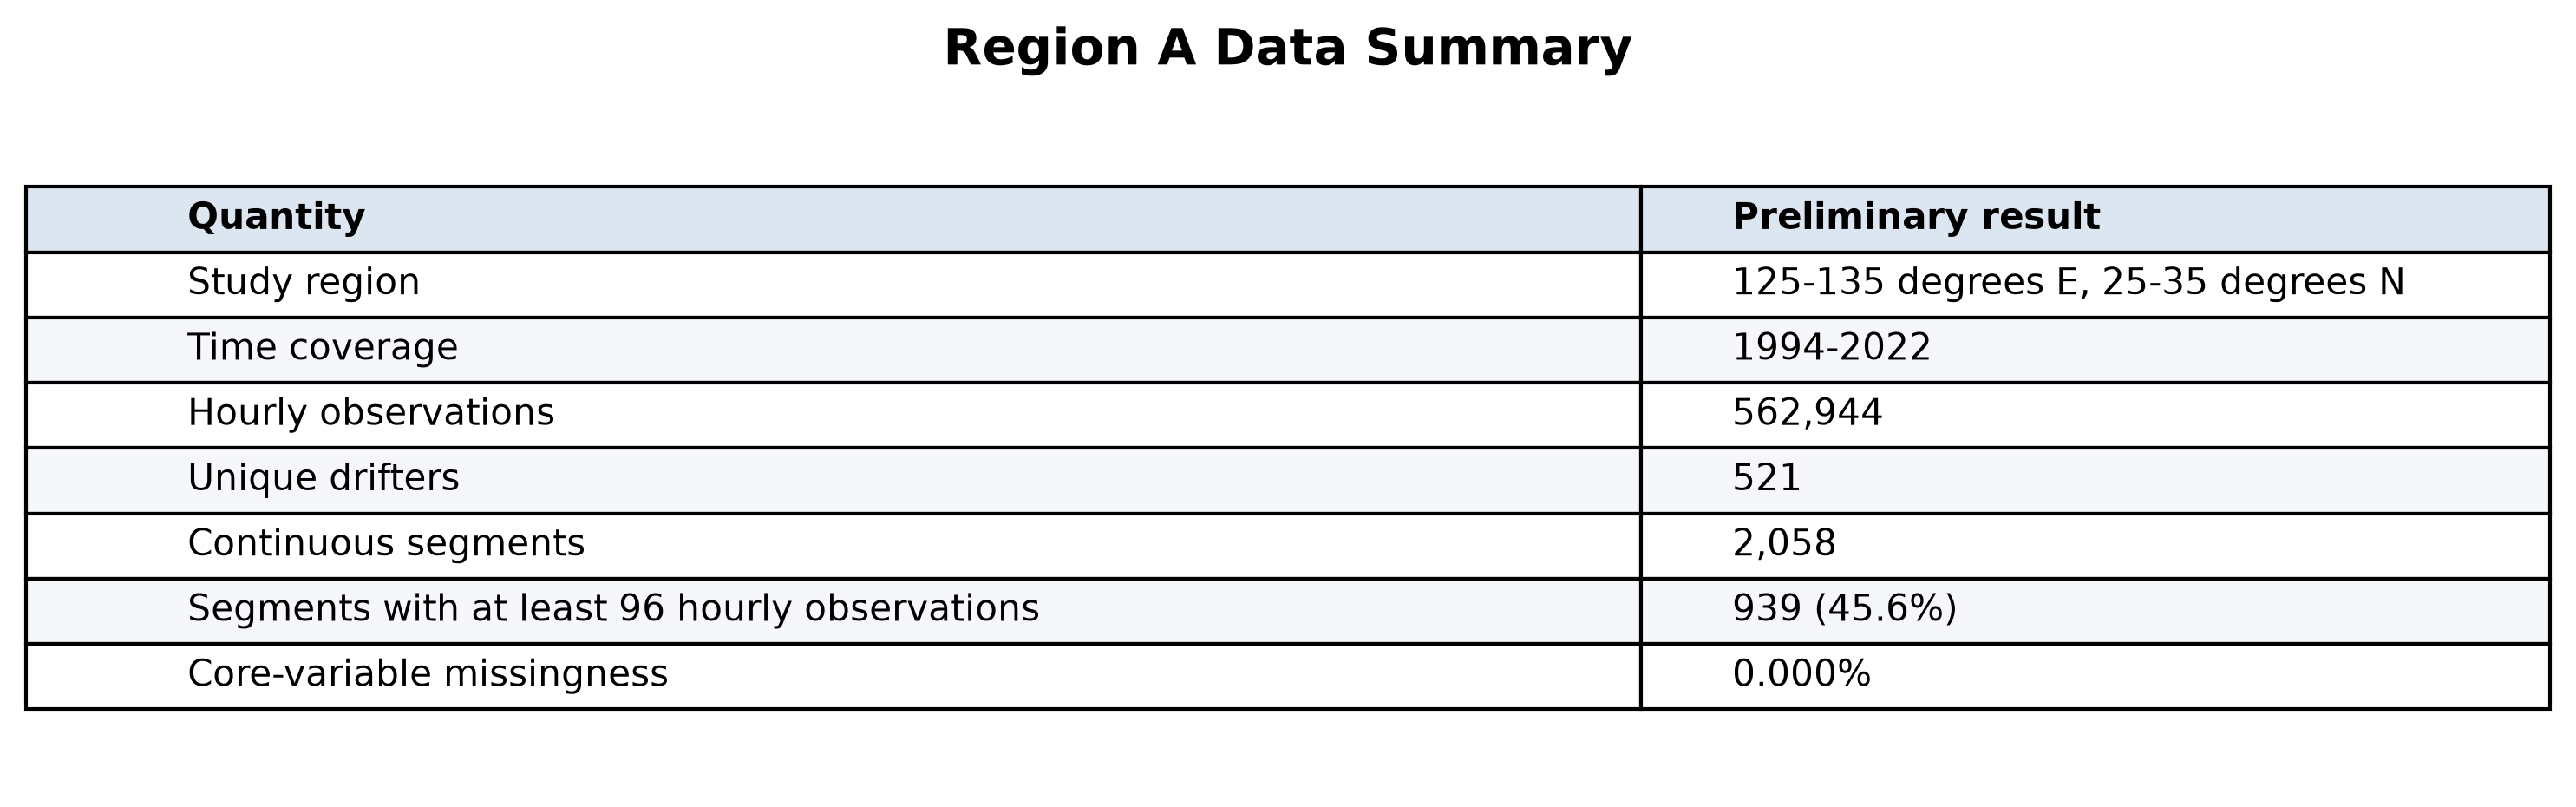

Saved: /Users/roger/Documents/data3001-project/outputs/figures/region_A_proposal_summary.csv
Saved: /Users/roger/Documents/data3001-project/outputs/figures/region_A_proposal_summary_table.png


In [24]:
from IPython.display import Image as NotebookImage

core_variables = [
    "ID", "time", "latitude", "longitude", "ve", "vn"
]
available_core = [
    column for column in core_variables if column in df.columns
]
core_missing_pct = (
    100 * df[available_core].isna().to_numpy().mean()
)
eligible_segments = int(
    segments["usable_for_24_to_72"].sum()
)
eligible_percentage = 100 * eligible_segments / len(segments)

proposal_summary = pd.DataFrame(
    {
        "Quantity": [
            "Study region",
            "Time coverage",
            "Hourly observations",
            "Unique drifters",
            "Continuous segments",
            "Segments with at least 96 hourly observations",
            "Core-variable missingness",
        ],
        "Preliminary result": [
            "125-135 degrees E, 25-35 degrees N",
            f"{df['time'].min().year}-{df['time'].max().year}",
            f"{len(df):,}",
            f"{df['ID'].nunique():,}",
            f"{len(segments):,}",
            f"{eligible_segments:,} ({eligible_percentage:.1f}%)",
            f"{core_missing_pct:.3f}%",
        ],
    }
)

summary_csv_path = OUTPUT_DIR / "region_A_proposal_summary.csv"
proposal_summary.to_csv(summary_csv_path, index=False)
display(proposal_summary)

table_fig, table_ax = plt.subplots(figsize=(10, 3.2))
table_ax.axis("off")
summary_table = table_ax.table(
    cellText=proposal_summary.values,
    colLabels=proposal_summary.columns,
    colWidths=[0.64, 0.36],
    cellLoc="left",
    colLoc="left",
    loc="center",
)
summary_table.auto_set_font_size(False)
summary_table.set_fontsize(10)
summary_table.scale(1, 1.45)
for (row, _column), cell in summary_table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#DCE6F1")
        cell.set_text_props(weight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#F5F7FA")
table_ax.set_title(
    "Region A Data Summary", fontsize=14, fontweight="bold", pad=14
)
table_fig.tight_layout()
summary_table_path = (
    OUTPUT_DIR / "region_A_proposal_summary_table.png"
)
table_fig.savefig(summary_table_path, dpi=300, bbox_inches="tight")
plt.close(table_fig)

display(NotebookImage(filename=str(summary_table_path)))

print("Saved:", summary_csv_path)
print("Saved:", summary_table_path)

### 14.2 Preliminary-analysis figure

Panel (a) displays hourly observation counts in 0.25-degree grid cells using a logarithmic colour scale. A blank cell means that no observation was recorded in that cell; it should not be interpreted automatically as land. Panel (b) displays the distribution of continuous-segment lengths and marks the 96-hour eligibility threshold.

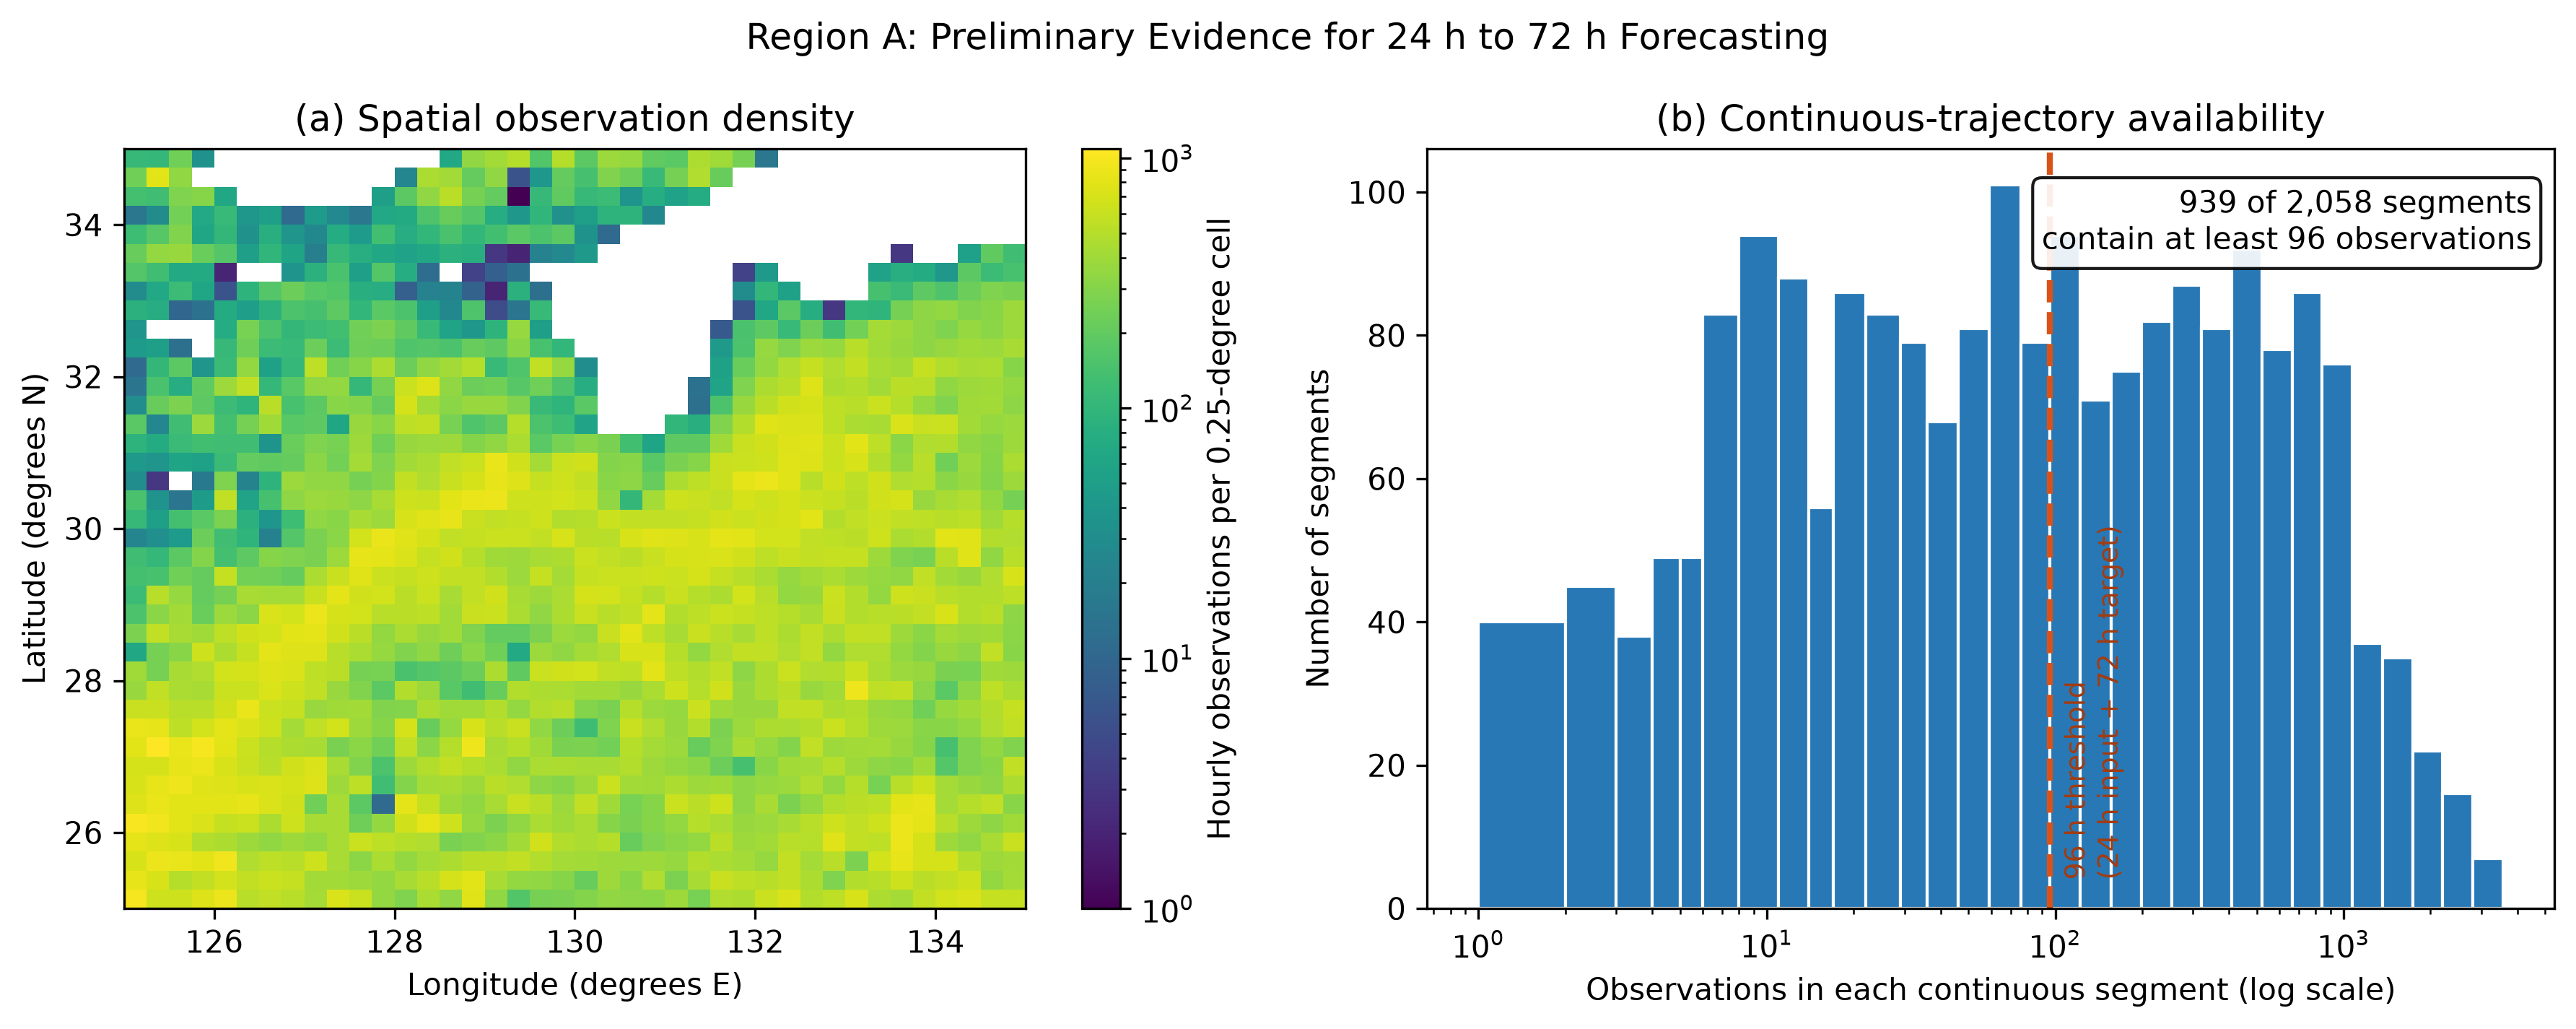

Saved: /Users/roger/Documents/data3001-project/outputs/figures/region_A_proposal_preliminary_analysis.png


In [25]:
from matplotlib.colors import LogNorm

proposal_grid_size = 0.25
proposal_lon_edges = np.arange(
    LON_MIN, LON_MAX + proposal_grid_size, proposal_grid_size
)
proposal_lat_edges = np.arange(
    LAT_MIN, LAT_MAX + proposal_grid_size, proposal_grid_size
)
proposal_density, _, _ = np.histogram2d(
    df["lon"],
    df["lat"],
    bins=[proposal_lon_edges, proposal_lat_edges],
)
proposal_density = np.ma.masked_where(
    proposal_density.T == 0, proposal_density.T
)

segment_lengths = segments["n_observations"].clip(lower=1)
maximum_segment_length = max(int(segment_lengths.max()), 96)
segment_length_bins = np.unique(
    np.logspace(
        0, np.log10(maximum_segment_length + 1), 35
    ).astype(int)
)
if segment_length_bins[-1] <= maximum_segment_length:
    segment_length_bins = np.append(
        segment_length_bins, maximum_segment_length + 1
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
density_mesh = axes[0].pcolormesh(
    proposal_lon_edges,
    proposal_lat_edges,
    proposal_density,
    shading="auto",
    cmap="viridis",
    norm=LogNorm(
        vmin=1, vmax=float(proposal_density.max())
    ),
)
fig.colorbar(
    density_mesh,
    ax=axes[0],
    label="Hourly observations per 0.25-degree cell",
)
axes[0].set(
    xlim=(LON_MIN, LON_MAX),
    ylim=(LAT_MIN, LAT_MAX),
    xlabel="Longitude (degrees E)",
    ylabel="Latitude (degrees N)",
    title="(a) Spatial observation density",
)

axes[1].hist(
    segment_lengths,
    bins=segment_length_bins,
    color="#2878B5",
    edgecolor="white",
)
axes[1].axvline(
    96,
    color="#D95319",
    linestyle="--",
    linewidth=2,
)
axes[1].set_xscale("log")
axes[1].set(
    xlabel="Observations in each continuous segment (log scale)",
    ylabel="Number of segments",
    title="(b) Continuous-trajectory availability",
)
axes[1].text(
    0.98,
    0.95,
    (
        f"{eligible_segments:,} of {len(segments):,} segments\n"
        "contain at least 96 observations"
    ),
    transform=axes[1].transAxes,
    ha="right",
    va="top",
    bbox={
        "boxstyle": "round",
        "facecolor": "white",
        "alpha": 0.9,
    },
)
axes[1].text(
    105,
    4,
    "96 h threshold\n(24 h input + 72 h target)",
    rotation=90,
    ha="left",
    va="bottom",
    color="#A13C13",
    fontsize=9,
)

fig.suptitle(
    "Region A: Preliminary Evidence for 24 h to 72 h Forecasting"
)
fig.tight_layout()
proposal_figure_path = (
    OUTPUT_DIR / "region_A_proposal_preliminary_analysis.png"
)
fig.savefig(proposal_figure_path, dpi=300, bbox_inches="tight")
plt.close(fig)
display(NotebookImage(filename=str(proposal_figure_path)))
print("Saved:", proposal_figure_path)

### Interpretation for the proposal

The spatial-density map demonstrates broad but uneven coverage within Region A. The segment-length distribution shows that **939 of 2,058 segments (45.6%)** contain at least 96 hourly observations and can therefore support a 24-hour input and a 72-hour target. These results provide direct preliminary evidence that the forecasting design is feasible. However, forecasting windows from the same segment share many observations and must not be treated as statistically independent; this motivates temporally spaced forecast origins and drifter-level data partitioning.